<a href="https://colab.research.google.com/github/mohith890417/ml-lab/blob/main/Diabetes_Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix,precision_score,recall_score

In [ ]:
df = pd.read_excel("/content/diabetesxl.xlsx")
df.head()

,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   preg    768 non-null    int64  
 1   plas    768 non-null    int64  
 2   pres    768 non-null    int64  
 3   skin    768 non-null    int64  
 4   insu    768 non-null    int64  
 5   mass    768 non-null    float64
 6   pedi    768 non-null    float64
 7   age     768 non-null    int64  
 8   class   768 non-null    object 
dtypes: float64(2), int64(6), object(1)
memory usage: 54.1+ KB


In [ ]:
df.isnull().sum()

,0
preg,0
plas,0
pres,0
skin,0
insu,0
mass,0
pedi,0
age,0
class,0


In [ ]:
x = df[['age','mass','insu','plas']]
y = df['class']


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
print("Records for training:",len(x_train))
print("Records for testing:",len(x_test))

Records for training: 614
Records for testing: 154


train random forest

In [ ]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(x_train, y_train)
y_predict = model.predict(x_test)

In [ ]:
logr.fit(x_train, y_train)

RandomForestClassifier()

In [ ]:
y_predict = logr.predict(x_test)
result = pd.DataFrame({'Actual': y_test,

                       'Predicted': y_predict

                       })
result.head(10)

,Actual,Predicted
668,tested_negative,tested_positive
324,tested_negative,tested_positive
624,tested_negative,tested_negative
690,tested_negative,tested_negative
473,tested_negative,tested_positive
204,tested_negative,tested_positive
97,tested_negative,tested_negative
336,tested_negative,tested_positive
568,tested_negative,tested_negative
148,tested_negative,tested_positive


In [ ]:
age = int(input("Enter age:"))
mass = int(input("Enter mass:"))
insu = int(input("Enter insu:"))
plas = int(input("Enter plas:"))
input_df = pd.DataFrame([[age, mass, insu, plas]], columns=['age', 'mass', 'insu', 'plas'])
predict = logr.predict(input_df)

if predict[0] == 1:
  print("you will die")
else:
  print("eat laddu")

Enter age:25
Enter mass:55
Enter insu:124
Enter plas:33
eat laddu


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_predict))
print("Precision:", precision_score(y_test, y_predict, pos_label='tested_positive'))
print("Recall:", recall_score(y_test, y_predict, pos_label='tested_positive'))
print("F1 Score:", f1_score(y_test, y_predict, pos_label='tested_positive'))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_predict))

Accuracy: 0.7142857142857143
Precision: 0.5873015873015873
Recall: 0.6727272727272727
F1 Score: 0.6271186440677966
Confusion Matrix:
 [[73 26]
 [18 37]]


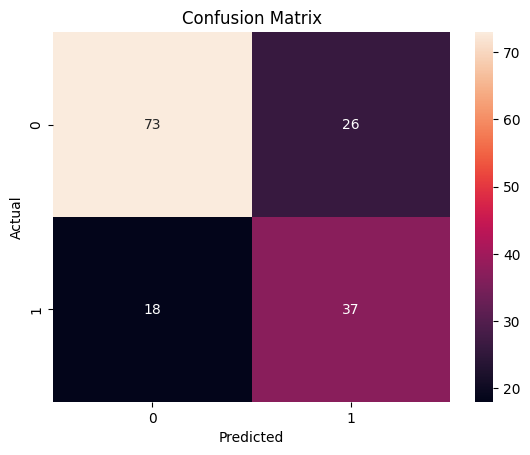

In [ ]:
import seaborn as sns
cm = confusion_matrix(y_test, y_predict)
sns.heatmap(cm, annot=True)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from sklearn.tree import plot_tree


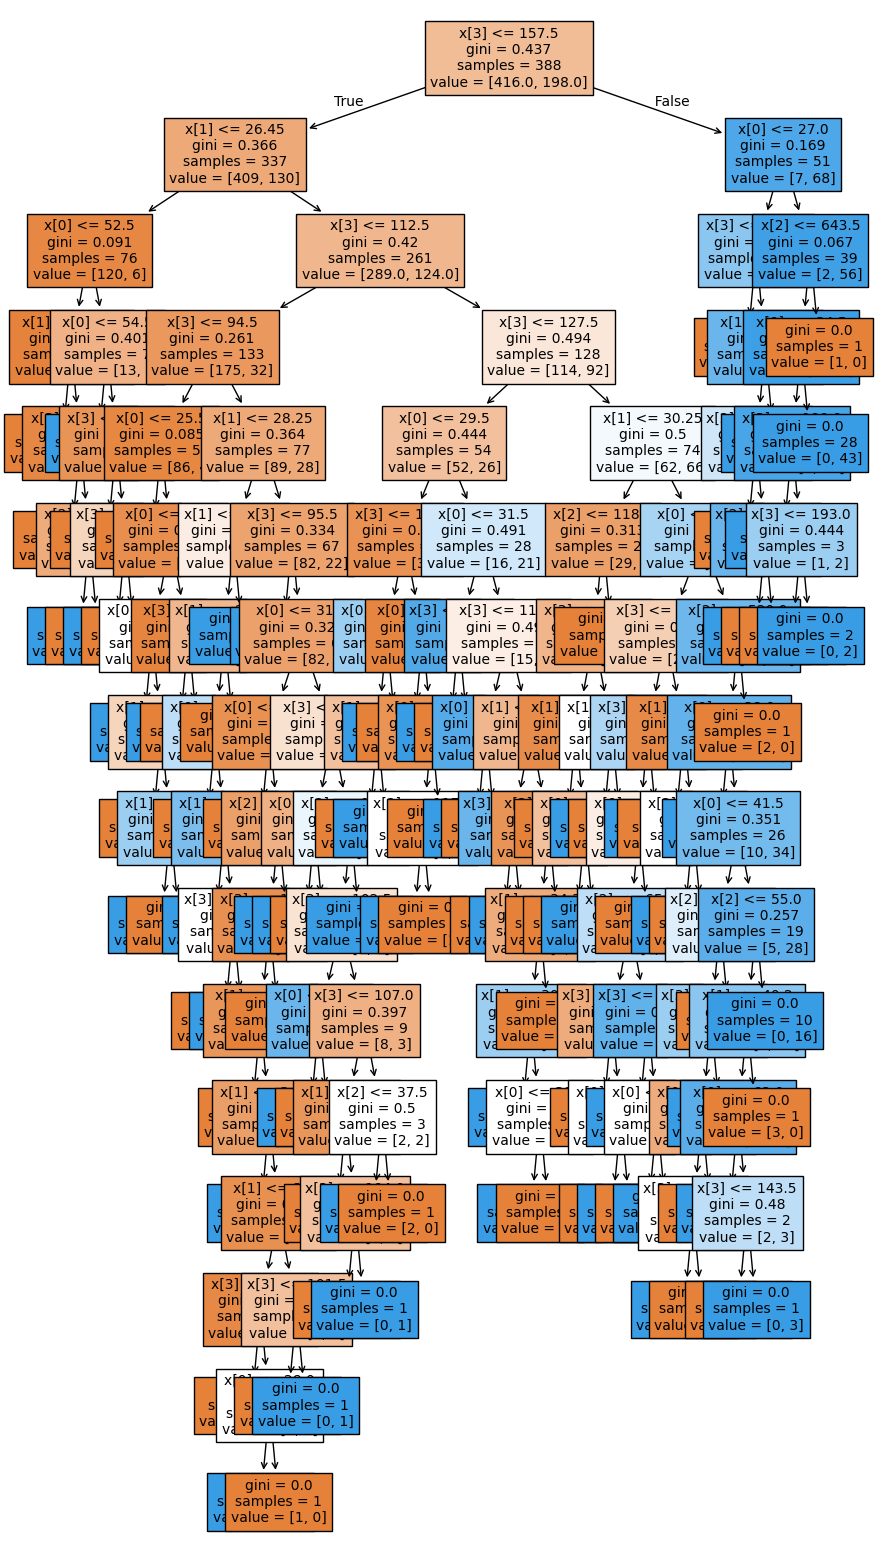

In [ ]:
plt.figure(figsize=(10, 20))
plot_tree(logr.estimators_[0], fontsize=10, filled=True)
plt.savefig("RandomForestClassifier.pdf")